In [1]:
import pandas as pd

df = pd.read_csv("../telco_churn.csv")

print(df.shape)
print(df.dtypes)
print(df.head())
print("Duplicate rows:", df.duplicated().sum())
print(df.isnull().sum())
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True))

(7043, 21)
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45    

In [2]:
# 1. Convert TotalCharges to numeric; blanks become NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# 2. Now the missing values show up
print(df["TotalCharges"].isnull().sum())

# 3. Look at those rows
print(df[df["TotalCharges"].isnull()][["tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

# 4. Drop the ID column, then recheck duplicates
df = df.drop(columns=["customerID"])
print("Duplicate rows after dropping ID:", df.duplicated().sum())

11
      tenure  MonthlyCharges  TotalCharges Churn
488        0           52.55           NaN    No
753        0           20.25           NaN    No
936        0           80.85           NaN    No
1082       0           25.75           NaN    No
1340       0           56.05           NaN    No
3331       0           19.85           NaN    No
3826       0           25.35           NaN    No
4380       0           20.00           NaN    No
5218       0           19.70           NaN    No
6670       0           73.35           NaN    No
6754       0           61.90           NaN    No
Duplicate rows after dropping ID: 22


In [3]:
from sklearn.model_selection import train_test_split

# 1. Remove duplicates
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

# 2. Separate features and target (Yes -> 1, No -> 0)
X = df.drop(columns="Churn")
y = (df["Churn"] == "Yes").astype(int)

# 3. Stratified 80:20 split with a fixed seed
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 4. Check the split sizes and class balance
print(X_train.shape, X_test.shape)
print("Full :", y.mean().round(4))
print("Train:", y_train.mean().round(4))
print("Test :", y_test.mean().round(4))

# 5. Save the test set for the GitHub repo (test_data.csv)
pd.concat([X_test, y_test], axis=1).to_csv("../test_data.csv", index=False)

Shape after removing duplicates: (7021, 20)
(5616, 19) (1405, 19)
Full : 0.2645
Train: 0.2644
Test : 0.2648


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Column groups
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X_train.columns
            if c not in num_cols + ["SeniorCitizen"]]
# SeniorCitizen is already 0/1, so it passes through unchanged

num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

cat_pipe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

preprocessor = ColumnTransformer(
    [
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols),
    ],
    remainder="passthrough",   # keeps SeniorCitizen
)

# FIT on training data only, then TRANSFORM both sets
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

print("Before:", X_train.shape, "->", "After:", X_train_p.shape)
print("Any NaN left in train?", pd.DataFrame(X_train_p).isnull().sum().sum())
print("Any NaN left in test? ", pd.DataFrame(X_test_p).isnull().sum().sum())

Before: (5616, 19) -> After: (5616, 45)
Any NaN left in train? 0
Any NaN left in test?  0


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "kNN": KNeighborsClassifier(n_neighbors=11),
    "Naive Bayes": GaussianNB(),
    "Random Forest (Ensemble)": RandomForestClassifier(n_estimators=200, random_state=42),
}

rows = []
for name, model in models.items():
    model.fit(X_train_p, y_train)
    pred = model.predict(X_test_p)
    prob = model.predict_proba(X_test_p)[:, 1]   # probability of churn, needed for AUC
    rows.append({
        "ML Model Name": name,
        "Accuracy": accuracy_score(y_test, pred),
        "AUC": roc_auc_score(y_test, prob),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "MCC": matthews_corrcoef(y_test, pred),
    })

results = pd.DataFrame(rows).set_index("ML Model Name").round(4)
print(results)

                          Accuracy     AUC  Precision  Recall      F1     MCC
ML Model Name                                                                
Logistic Regression         0.8028  0.8403     0.6610  0.5242  0.5847  0.4630
Decision Tree               0.7943  0.8287     0.6203  0.5753  0.5969  0.4597
kNN                         0.7744  0.8091     0.5857  0.5054  0.5426  0.3958
Naive Bayes                 0.6861  0.8092     0.4501  0.8360  0.5851  0.4132
Random Forest (Ensemble)    0.7786  0.8161     0.6078  0.4624  0.5252  0.3904


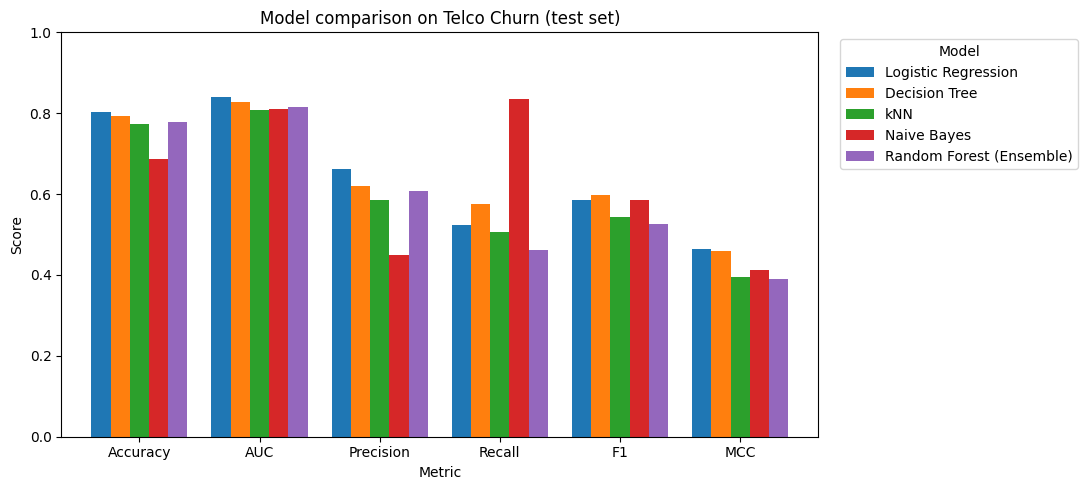

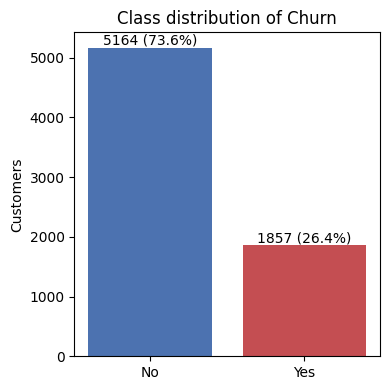

In [6]:
import matplotlib.pyplot as plt

# 1. Grouped bar chart: all metrics, all models
ax = results.T.plot(kind="bar", figsize=(11, 5), width=0.8)
ax.set_title("Model comparison on Telco Churn (test set)")
ax.set_ylabel("Score")
ax.set_xlabel("Metric")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("../metrics_comparison.png", dpi=150)
plt.show()

# 2. Class distribution chart
counts = df["Churn"].value_counts()
plt.figure(figsize=(4, 4))
plt.bar(counts.index, counts.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(counts.values):
    plt.text(i, v + 50, f"{v} ({v / counts.sum():.1%})", ha="center")
plt.title("Class distribution of Churn")
plt.ylabel("Customers")
plt.tight_layout()
plt.savefig("../class_distribution.png", dpi=150)
plt.show()

In [7]:
results.to_csv("../results_table.csv")

In [8]:
import numpy, matplotlib, sklearn
print(sklearn.__version__, pd.__version__, numpy.__version__, matplotlib.__version__)

1.9.1 2.2.3 2.5.5 3.10.1
